# Pipeline A — Investment Trends & Evolution (2019–2026)

**Question:** How has reported business investment in Kosovo evolved over 2019–2026, how did the COVID-19 pandemic affect it, and is there a regular pattern within the year?

The data are monthly, eight years long and include a pandemic, so *time* is the natural first lens on them. Pipelines B (where) and C (import or domestic) look at the same data by place and by origin.

**Data:** the validated Common Dataset (124,262 monthly records, 2019 to June 2026). Each record is a group of businesses with the same year, month, sector, registration status and municipality, with six investment amounts reported in the VAT declaration. Pipeline A analyses each amount and their sum, `total_investment`.

**Two windows** run through every table, because 2026 covers January–June only:
- `reported`: every month supplied (2019–2025 complete, 2026 January–June);
- `jan_jun`: the same six months of every year, so 2026 can be compared fairly.

**Run first** (from the project root, with the project's `.venv`):
```
python -m phase_1.run_common_preprocessing
python -m phase_1.pipeline_a.run_pipeline_a
```
This notebook only reads and explains the saved outputs.

| Stage | Technique | Main outputs |
|---|---|---|
| 01 | Feature subset selection, aggregation (month → quarter → year) | `monthly`, `quarterly`, `annual`, `sector_monthly`, `cv_by_level` |
| 02 | Feature creation (growth, rolling means, seasonality, trend, pandemic recovery) | `monthly_features`, `annual_features`, `seasonality`, `trend_slope`, `recovery` |
| 03 | Transformation (index 2019 = 100, seasonal decomposition, log1p, z-score) | `annual_index`, `monthly_transformed`, `skewness` |
| 04 | Discretization and binarization | `monthly_discretized`, `annual_discretized`, `growth_class_comparison` |
| 05 | Sampling (bootstrap, 10% samples against the population) | `bootstrap_ci`, `sample_sensitivity` |
| 06 | Figures | `outputs/figures/pipeline_a/a01 … a09` |

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/schema.py').exists()), None)
if root is None:
    raise FileNotFoundError('Open the notebook inside the project folder.')
sys.path.insert(0, str(root))
from src.schema import MONEY
from src.io_utils import STATUS, digest
from phase_1.pipeline_a import TABLES, FIGURES, VALIDATION, MEASURES, MEASURE_LABELS, TOTAL, read_table

status = json.loads(VALIDATION.read_text(encoding='utf-8'))
common = json.loads(STATUS.read_text(encoding='utf-8'))
assert status['status'] == 'PASS', status
assert status['input_sha256'] == common['dataset_sha256'], 'Pipeline A was run on a different Common Dataset'
print('Input records:', status['input_records'], '| tables:', len(status['tables']), '| figures:', len(status['figures']))

SHORT = dict(zip(MEASURES, ['Mixed: no VAT', 'Mixed: non-deductible VAT', 'Imports 18%', 'Imports 8%',
                            'Domestic 18%', 'Domestic 8%', 'TOTAL']))
def figure(name):
    display(Image(filename=str(FIGURES / name)))
def by_measure(table, values, index='year'):
    return table.pivot(index=index, columns='measure', values=values)[MEASURES].rename(columns=SHORT)
pd.set_option('display.width', 160)

Input records: 124262 | tables: 16 | figures: 9


## 1. Feature subset selection and aggregation

Of the 25 columns of the Common Dataset, Pipeline A keeps the 9 that a time question needs: `year`, `month`, `primary_sector` (only for the recovery by sector) and the six amounts. Municipality, registration status, taxpayer count, provenance and review flags belong to other questions. One feature is added:

$$
\text{total\_investment} = \sum_{k=1}^{6} \text{amount}_k
$$

Records are then summed to four levels: month, quarter, year, and month × sector. Stage 01 checks that every level reproduces the source totals exactly.

The **coefficient of variation** shows how much each level fluctuates:

$$
CV = \frac{\text{standard deviation}}{\text{mean}}
$$

In [2]:
cv = read_table('cv_by_level')
display(cv.pivot(index='measure', columns='level', values='cv')[['monthly', 'quarterly', 'annual']].rename(index=SHORT).round(3))

level,monthly,quarterly,annual
measure,,,
Domestic 18%,0.483,0.402,0.364
Domestic 8%,0.766,0.520,0.325
Imports 18%,0.430,0.396,0.385
Imports 8%,1.109,0.758,0.588
Mixed: non-deductible VAT,0.438,0.359,0.285
Mixed: no VAT,0.620,0.456,0.346
TOTAL,0.451,0.379,0.335


**Reading:** for total investment the CV falls from **0.45** (months) to **0.38** (quarters) and **0.33** (years). Monthly totals are noisy, mostly because of the strong December (section 4); aggregation to years gives a stable series for the trend, while the monthly level is kept for seasonality and the pandemic.

## 2. Trend: how much did investment grow?

$$
\text{growth}_t = \frac{V_t - V_{t-1}}{V_{t-1}} \times 100
\qquad
\text{index}_t = \frac{V_t}{V_{2019}} \times 100
$$

A growth rate is only computed between periods with the same number of months (`comparable`), so 2026 is compared only in the `jan_jun` window. The trend slope is a straight line fitted through the complete years 2019–2025.

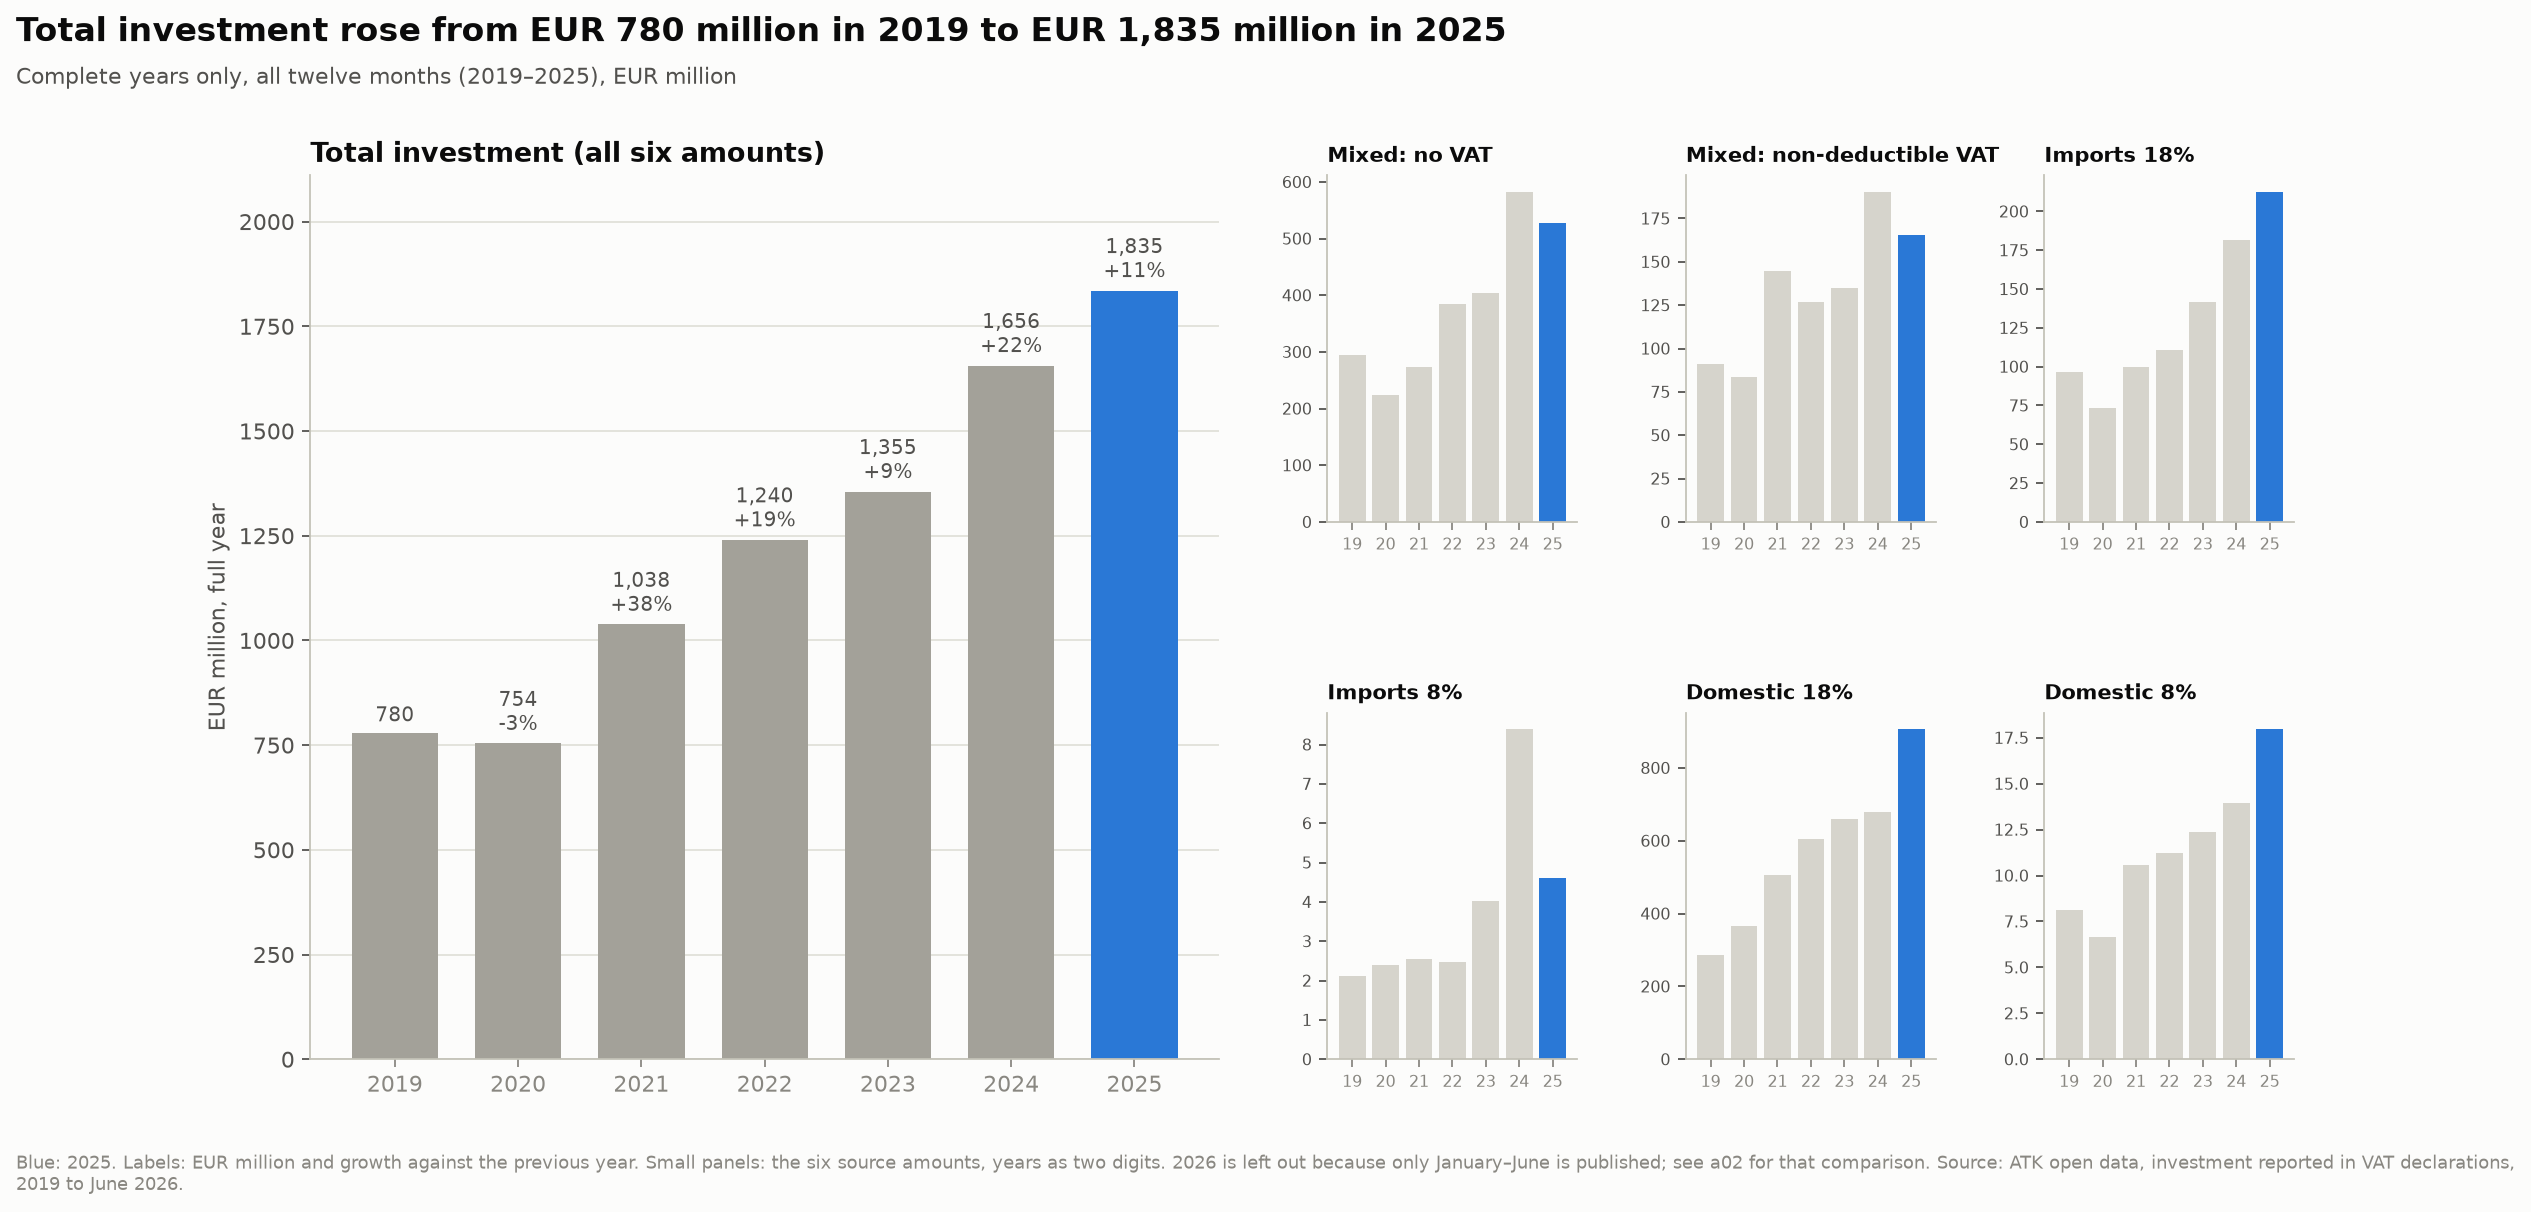

measure,Mixed: no VAT,Mixed: non-deductible VAT,Imports 18%,Imports 8%,Domestic 18%,Domestic 8%,TOTAL
year,,,,,,,
2019,295.0,91.1,96.6,2.1,286.6,8.1,779.5
2020,223.7,83.3,73.3,2.4,364.7,6.6,754.0
2021,273.5,144.6,99.9,2.6,507.3,10.6,1038.5
2022,385.2,127.0,111.0,2.5,603.4,11.2,1240.3
2023,404.0,135.0,141.7,4.0,658.4,12.4,1355.5
2024,582.7,190.4,181.9,8.4,679.1,13.9,1656.4
2025,528.2,165.3,212.7,4.6,906.6,18.0,1835.4


measure,Mixed: no VAT,Mixed: non-deductible VAT,Imports 18%,Imports 8%,Domestic 18%,Domestic 8%,TOTAL
year,,,,,,,
2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020,-24.1,-8.5,-24.1,13.1,27.2,-18.6,-3.3
2021,22.2,73.6,36.4,6.8,39.1,59.7,37.7
2022,40.8,-12.2,11.0,-3.4,19.0,5.9,19.4
2023,4.9,6.3,27.7,62.9,9.1,10.6,9.3
2024,44.2,41.1,28.4,108.4,3.1,12.4,22.2
2025,-9.3,-13.2,16.9,-45.0,33.5,29.0,10.8


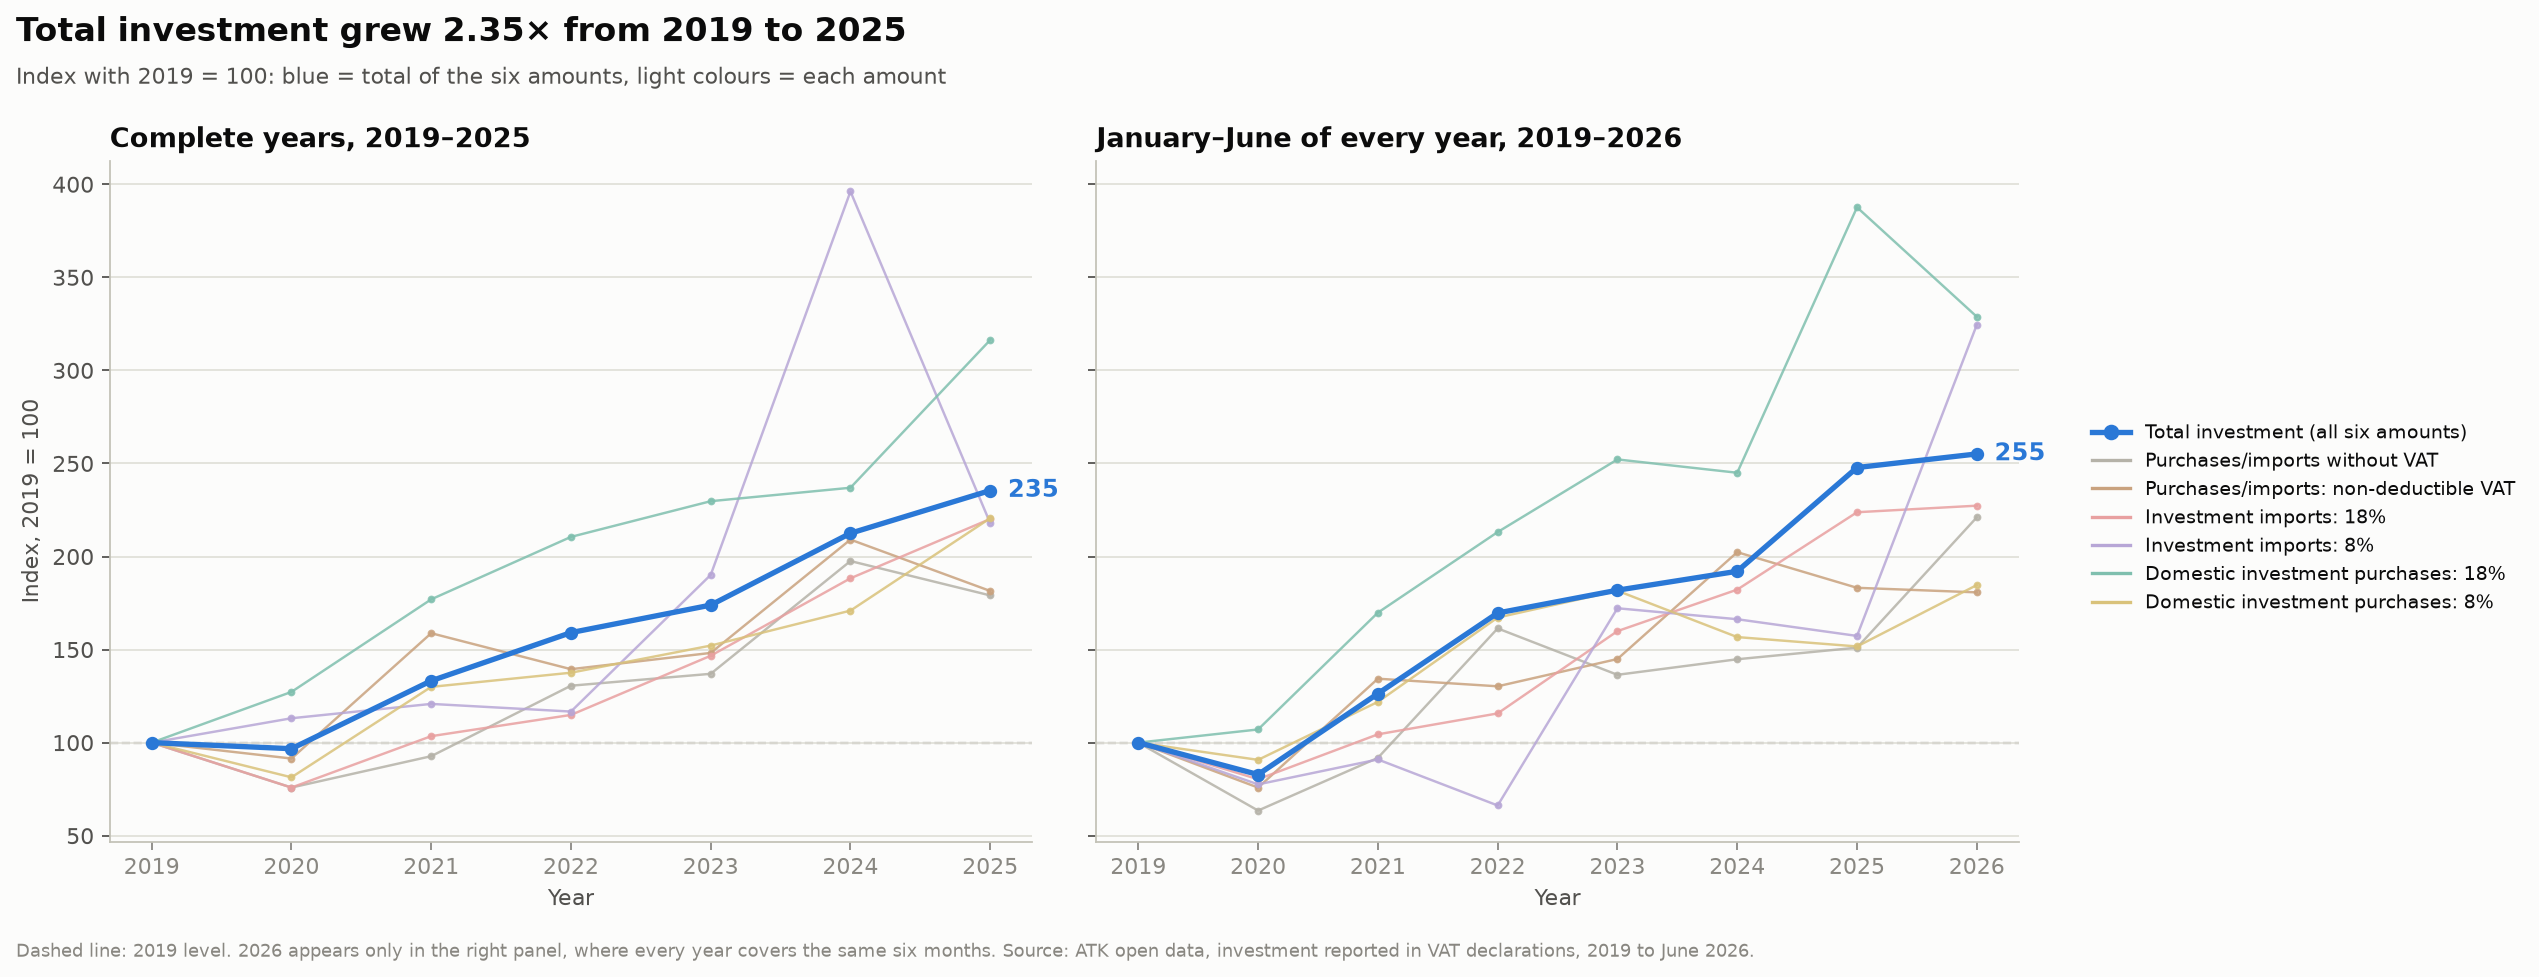

,window,years,slope_per_year,slope_pct_of_mean,r_squared
6,reported,7,1.889119e+08,15.271,0.970
13,jan_jun,8,8.431239e+07,14.893,0.944


In [3]:
figure('a09_full_year_totals.png')
annual = read_table('annual_features')
full = annual.query("window == 'reported' and not partial_year")
display(by_measure(full, 'value').div(1e6).round(1))
display(by_measure(full, 'yoy_pct').round(1))
figure('a01_index_2019.png')
display(read_table('trend_slope').query('measure == @TOTAL')[['window', 'years', 'slope_per_year', 'slope_pct_of_mean', 'r_squared']].round(3))

**Reading:**
- Total investment rose from **EUR 780 million in 2019 to EUR 1,835 million in 2025**, index **235**, i.e. 2.35 times the 2019 level.
- Growth was positive every year except **2020 (-3%)**. The largest increase came right after the pandemic, **2021 (+38%)**, followed by 2024 (+22%).
- The straight-line trend adds about **EUR 189 million a year (15% of the mean)**, with **R² = 0.97**: growth was steady, not driven by one exceptional year.
- Domestic purchases at 18% grew most (index 316). Imports at 8% jump to about 400 in 2024, but on a base of only about EUR 2 million, so a few purchases move that index a lot.

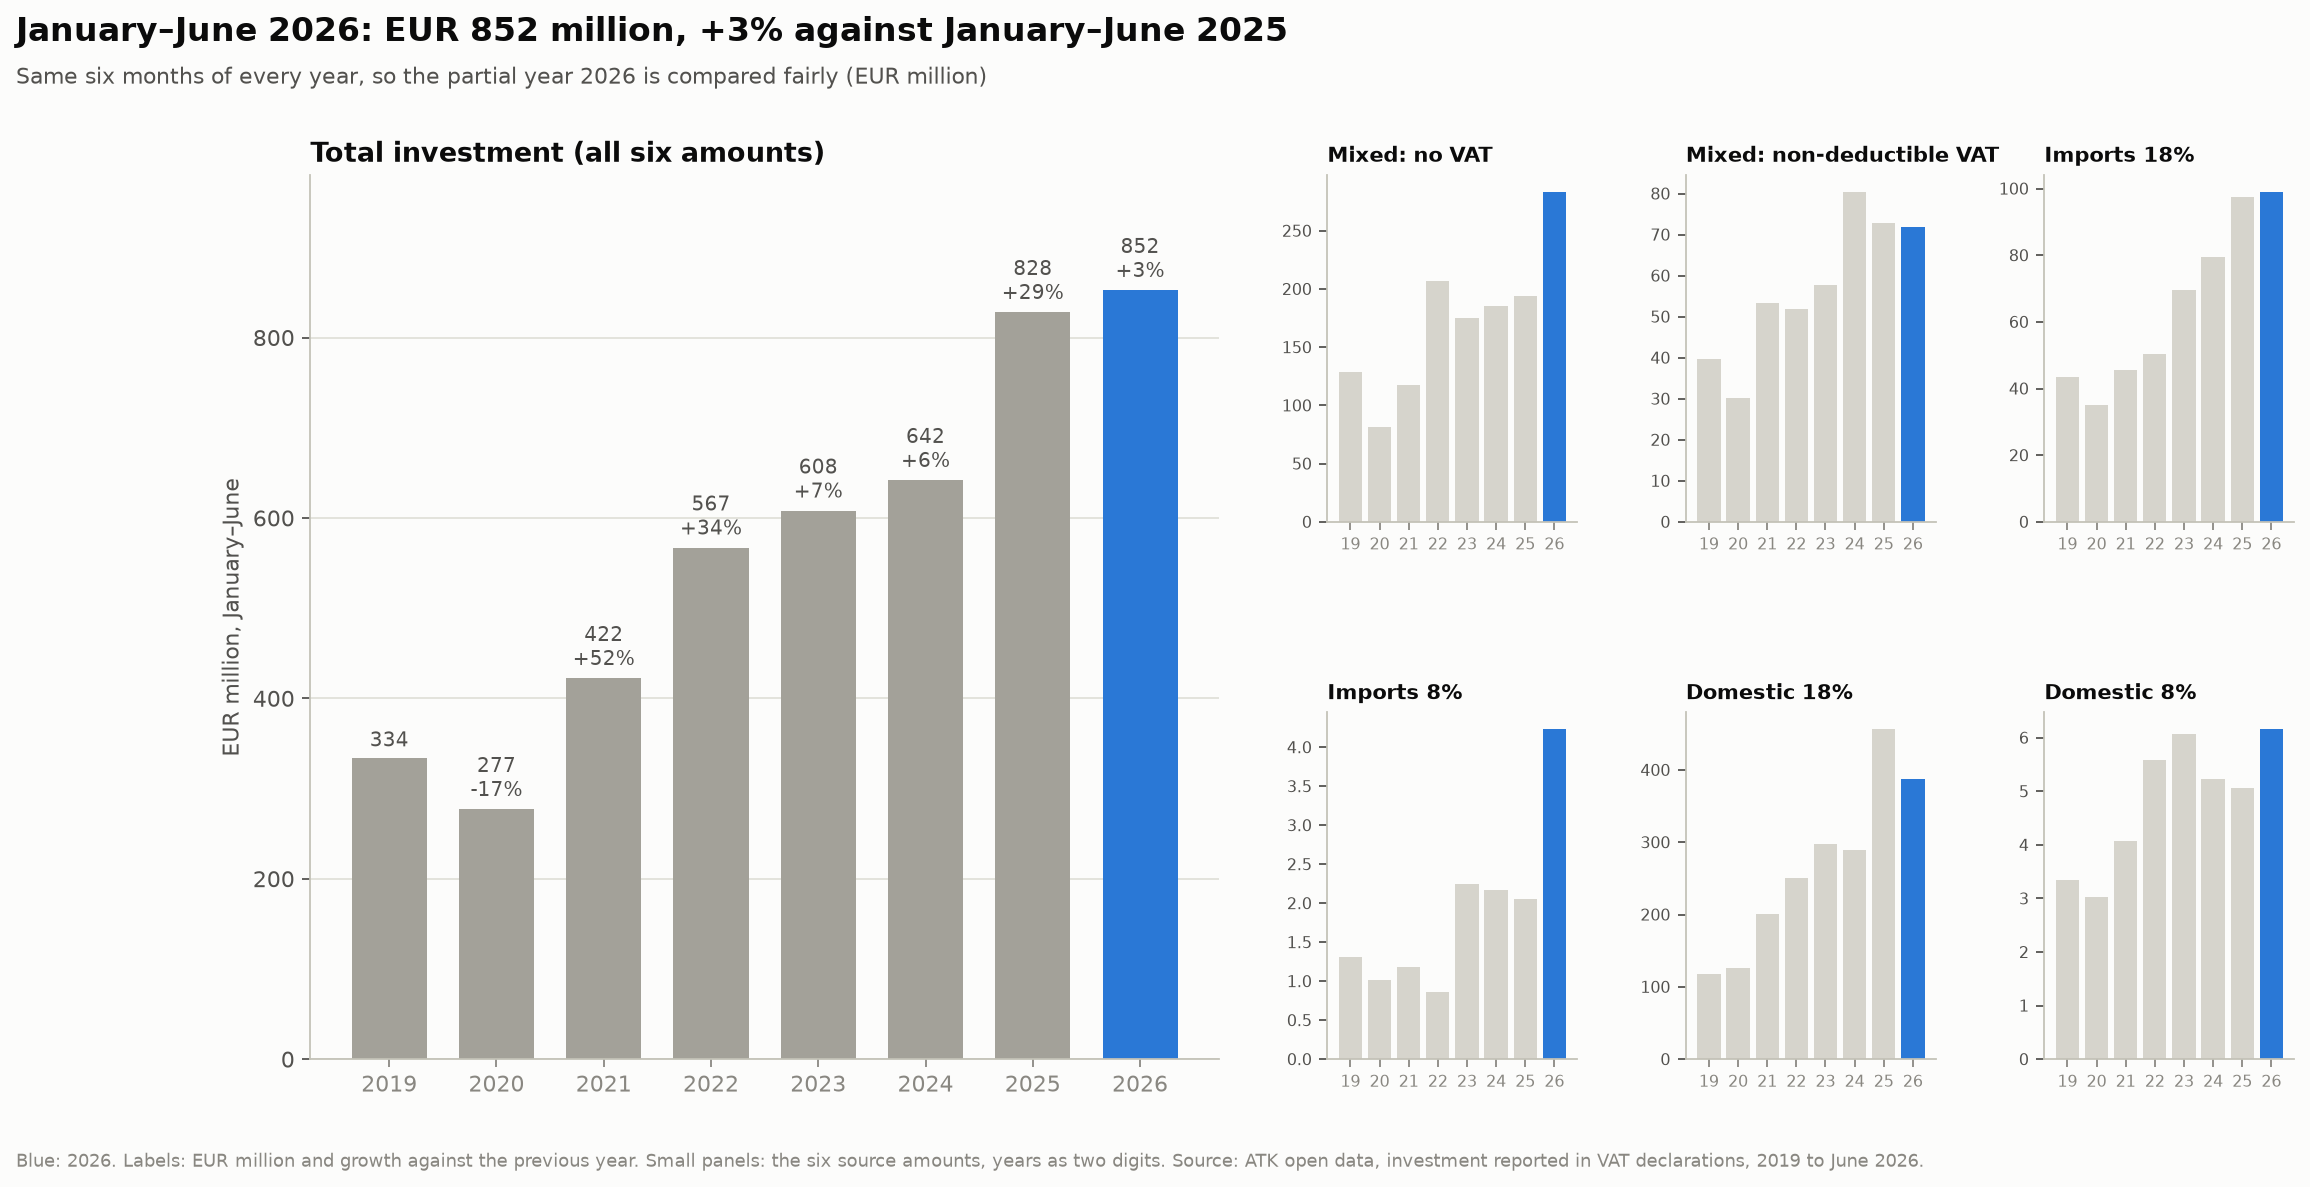

measure,Mixed: no VAT,Mixed: non-deductible VAT,Imports 18%,Imports 8%,Domestic 18%,Domestic 8%,TOTAL
year,,,,,,,
2019,128.3,39.8,43.6,1.3,117.8,3.3,334.1
2020,81.5,30.2,35.0,1.0,126.1,3.0,276.8
2021,117.8,53.4,45.5,1.2,200.0,4.1,422.0
2022,207.0,51.8,50.4,0.9,251.1,5.6,566.7
2023,175.0,57.6,69.7,2.2,297.0,6.1,607.7
2024,185.7,80.5,79.4,2.2,288.6,5.2,641.6
2025,193.7,72.8,97.5,2.1,456.6,5.1,827.8
2026,283.6,71.9,99.1,4.2,387.3,6.2,852.3


In [4]:
figure('a02_jan_jun_totals.png')
display(by_measure(annual.query("window == 'jan_jun'"), 'value').div(1e6).round(1))

**Reading:** January–June 2026 reached **EUR 852 million, +3% against January–June 2025** (EUR 828 million): investment is holding at the 2025 level rather than growing at the pace of earlier years. The composition changed: domestic purchases at 18% fell (-15%), while purchases and imports without VAT rose (+46%).

## 3. COVID-19: drop and recovery

Binary features `is_covid` (March 2020 – June 2021) and `is_lockdown` (March – May 2020) mark the pandemic months. For every amount and sector:

$$
\text{drop} = \left(\frac{\min \bar V^{(3)}_{\text{May 2020 … Feb 2021}}}{\bar V_{2019}} - 1\right)\times 100
$$

where $\bar V^{(3)}$ is the 3-month moving average and $\bar V_{2019}$ the 2019 monthly mean. The trough window starts in May 2020, so every 3-month average in it lies inside the pandemic and a strong January–February 2020 cannot hide the shock. **Recovery** is the first month *after the trough* whose 3-month average is back at or above the 2019 monthly mean; `recovery_months` counts from March 2020. A month without records for a sector counts as zero. Series that never fell below the baseline are marked `no_decline`. `Mungon aktiviteti` and `Person Fizik` are not sectors and are excluded from the sector ranking.

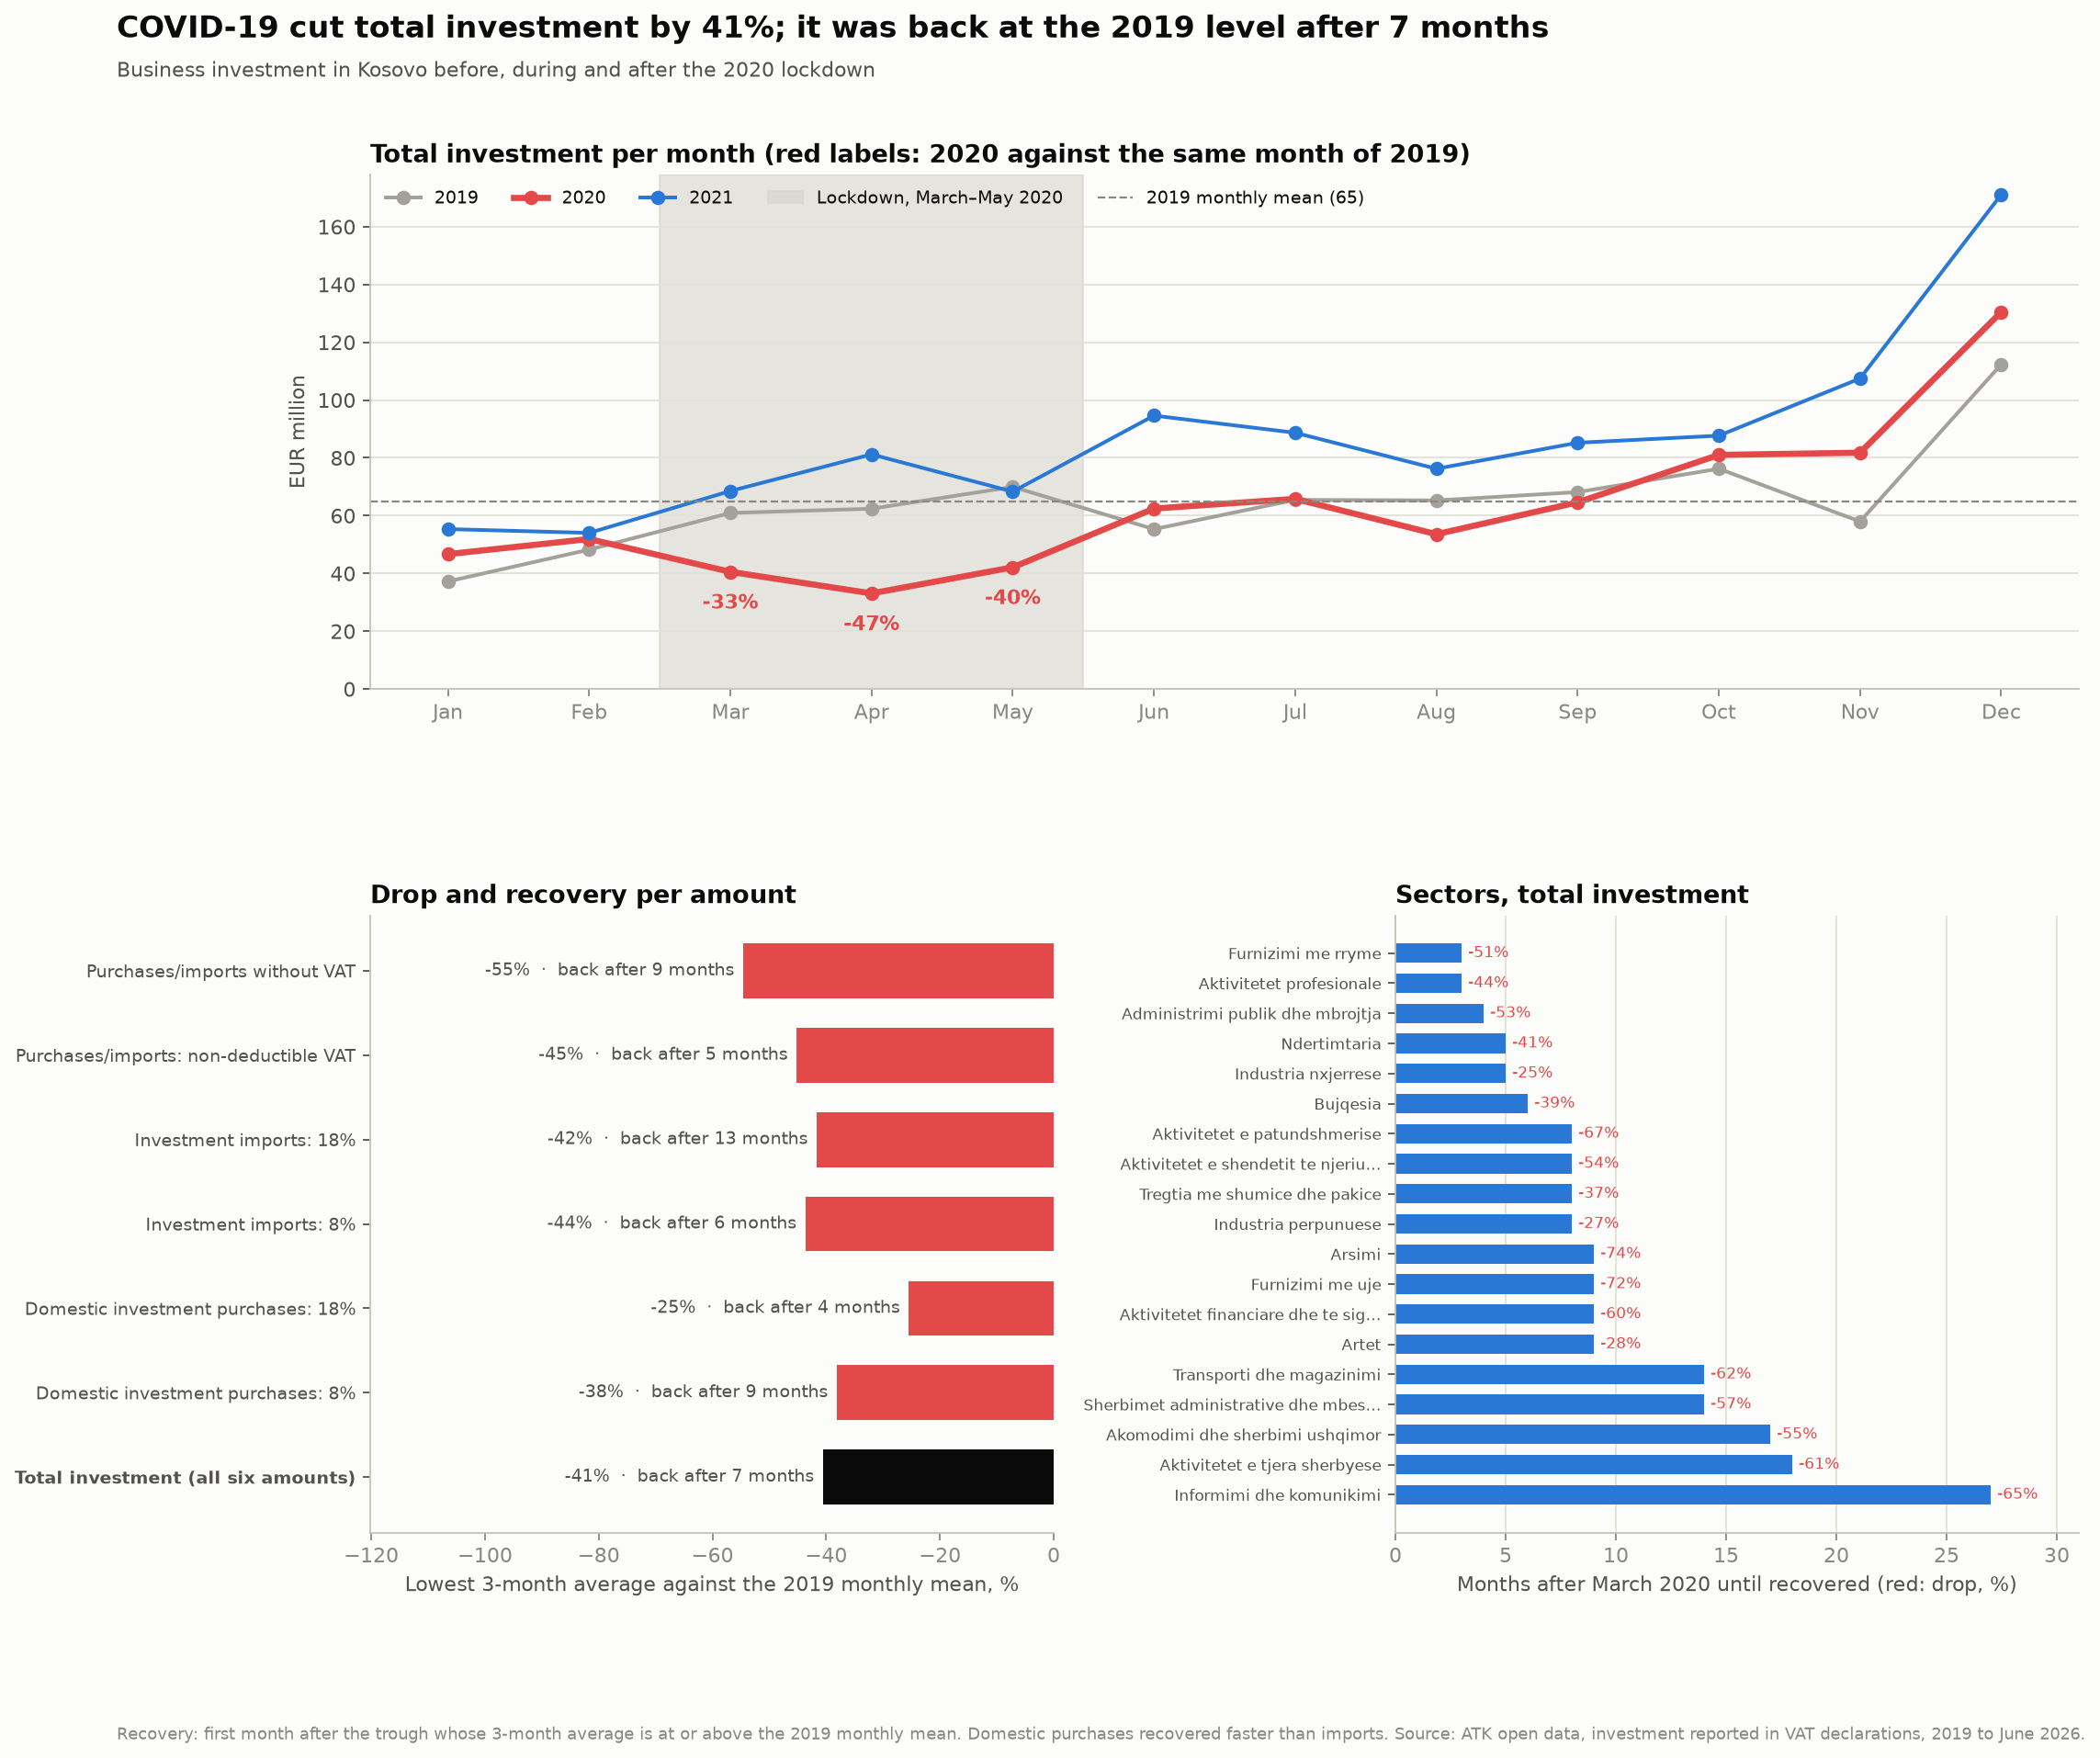

,baseline_2019_monthly,trough_year,trough_month,drop_pct,recovery_months,recovery_year,recovery_month
measure,,,,,,,
Mixed: no VAT,24579200.1,2020.0,5.0,-54.6,9.0,2020.0,12.0
Mixed: non-deductible VAT,7589259.3,2020.0,5.0,-45.2,5.0,2020.0,8.0
Imports 18%,8049620.3,2020.0,5.0,-41.7,13.0,2021.0,4.0
Imports 8%,176561.1,2020.0,7.0,-43.7,6.0,2020.0,9.0
Domestic 18%,23884865.8,2020.0,5.0,-25.5,4.0,2020.0,7.0
Domestic 8%,679093.5,2020.0,8.0,-38.2,9.0,2020.0,12.0
TOTAL,64958600.2,2020.0,5.0,-40.6,7.0,2020.0,10.0


In [5]:
figure('a08_covid.png')
recovery = read_table('recovery')
national = recovery.query("primary_sector == 'ALL'").set_index('measure').loc[MEASURES]
display(national[['baseline_2019_monthly', 'trough_year', 'trough_month', 'drop_pct', 'recovery_months', 'recovery_year', 'recovery_month']]
        .rename(index=SHORT).round(1))

**Reading:**
- During the lockdown, total investment fell **-33%, -47% and -40%** against March, April and May 2019. April 2020 (EUR 33 million) is the lowest month of the whole series.
- The lowest 3-month average was **-41%** below the 2019 monthly mean; it was back at that level after **7 months** (October 2020). The shock was deep but short: from June 2020 most months were at or above 2019 again.
- **Domestic purchases recovered fastest** (18%: -25%, back after 4 months); **imports slowest** (18%: -42%, back after 13 months), in line with closed borders and disrupted supply chains.
- Over the full year 2020 the total fell only -3%: the second half of the year made up for the spring.

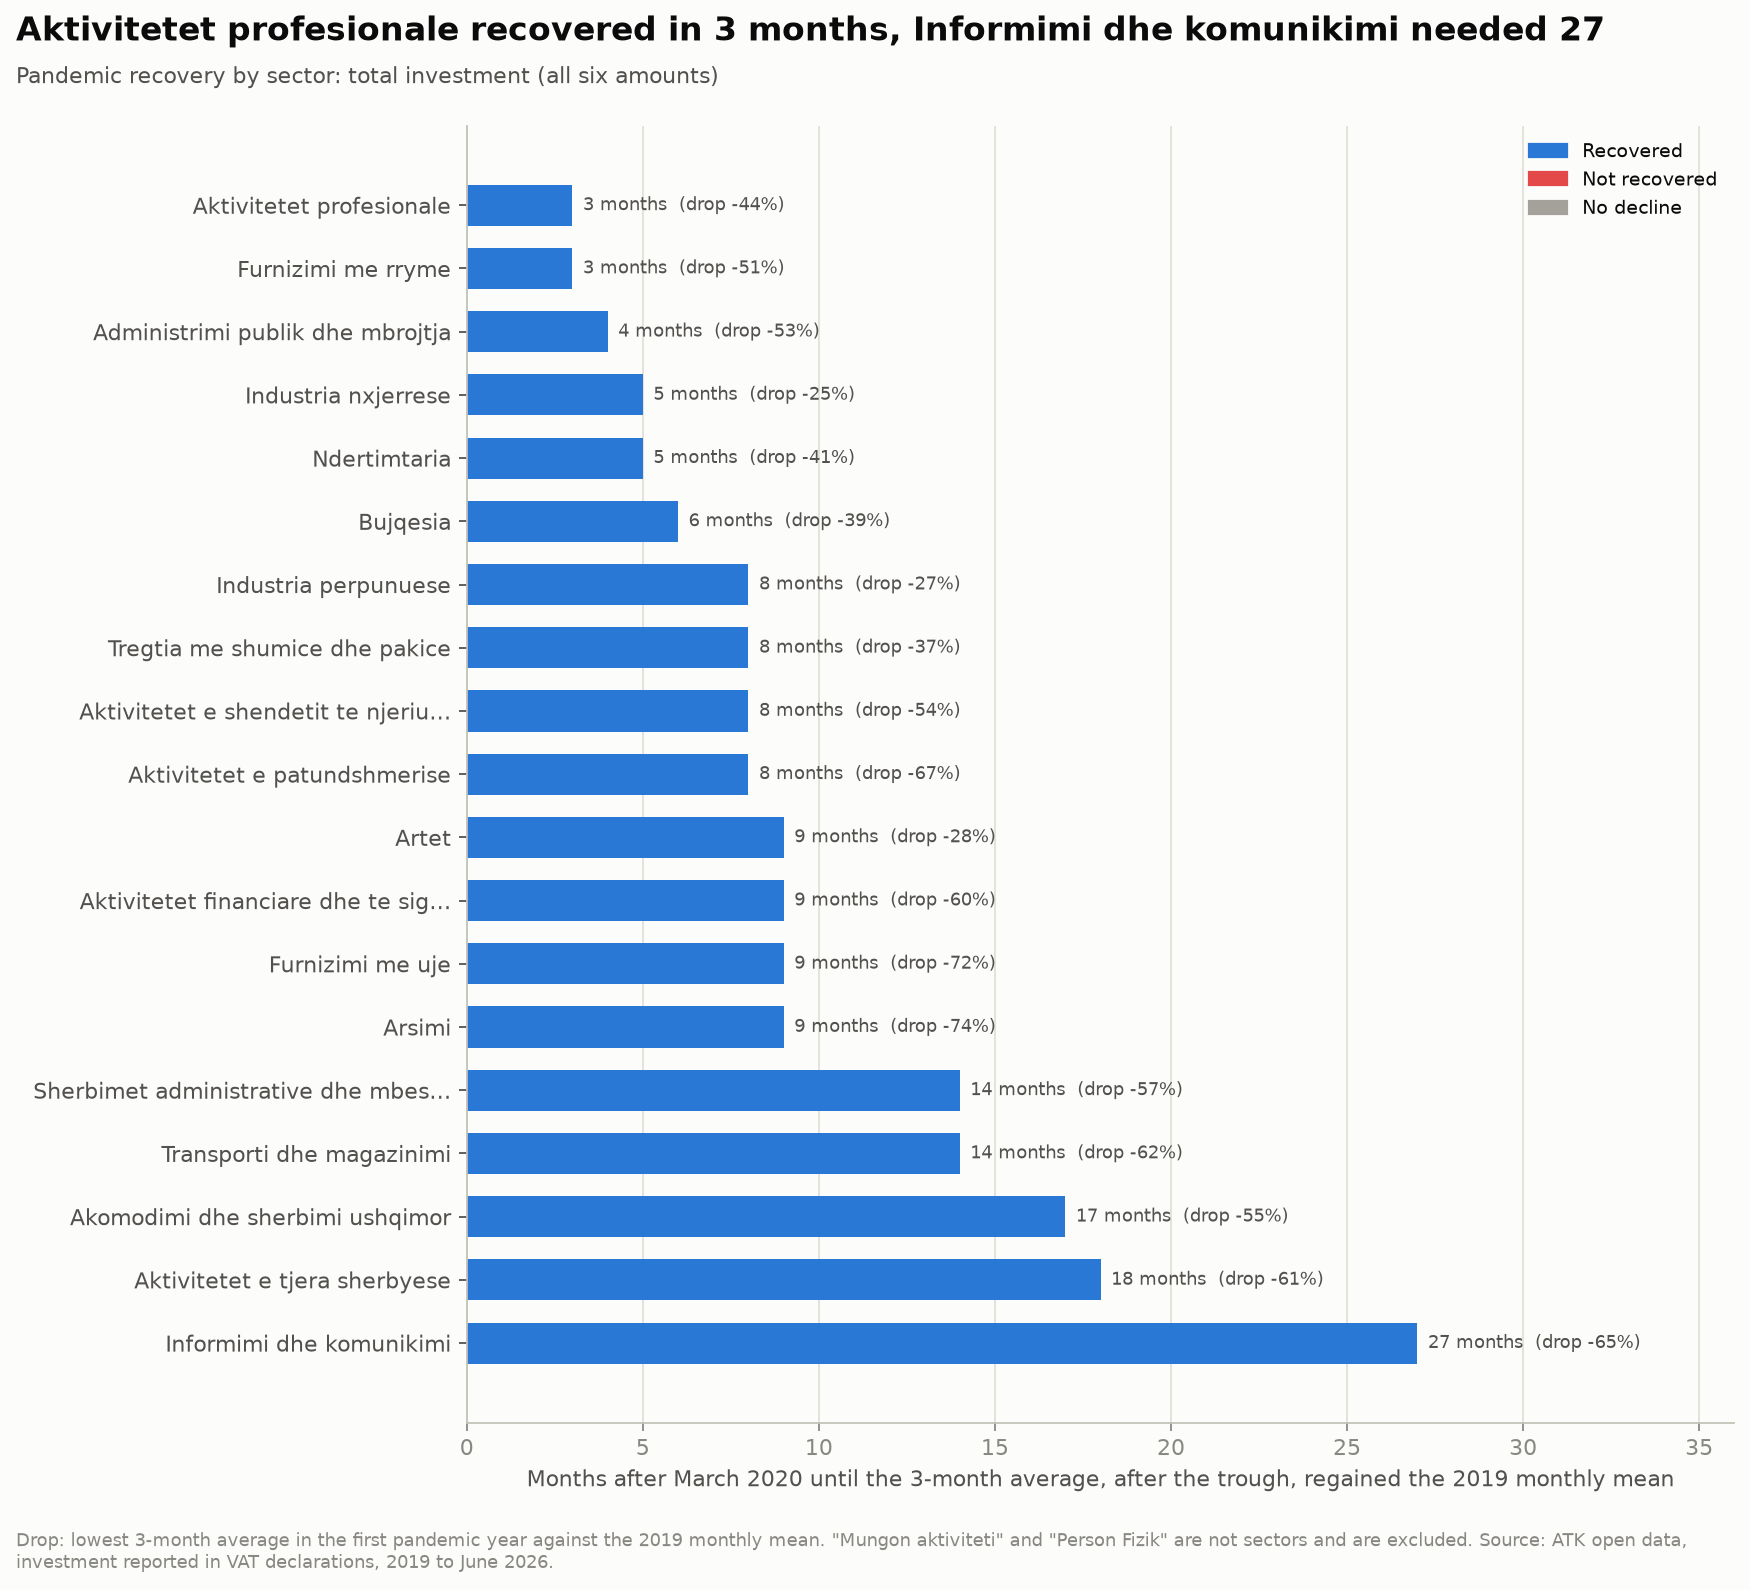

,primary_sector,status,drop_pct,recovery_months
0,"Aktivitetet profesionale, shkencore dhe teknike",valid,-44.2,3.0
1,"Furnizimi me rryme, gaz, avull dhe ajer te ko...",valid,-50.6,3.0
2,Administrimi publik dhe mbrojtja; Sigurimi soc...,valid,-52.9,4.0
3,Industria nxjerrese,valid,-24.7,5.0
4,Ndertimtaria,valid,-41.4,5.0
5,Bujqesia;Pylltaria dhe Peshkimi,valid,-39.0,6.0
6,Aktivitetet e shendetit te njeriut dhe te pune...,valid,-53.7,8.0
7,Aktivitetet e patundshmerise,valid,-66.8,8.0
8,Industria perpunuese,valid,-26.8,8.0
9,Tregtia me shumice dhe pakice; Riparimi i mjet...,valid,-37.3,8.0


In [6]:
figure('a05_recovery_by_sector.png')
sectors = recovery.query("measure == @TOTAL and status in ['valid', 'no_decline'] and primary_sector != 'ALL'")
display(sectors.sort_values('recovery_months')[['primary_sector', 'status', 'drop_pct', 'recovery_months']].round(1).reset_index(drop=True))

**Reading:** Furnizimi me rryme recovered in **3 months**; construction, mining and public administration within 5. The service sectors hit hardest by the closures took longest: accommodation and food (17 months), other services (18) and **Informimi dhe komunikimi (27)**. The deepest drops were in education and water supply (about −73%). Every sector recovered.

## 4. Seasonality and decomposition

$$
S_m = \mathrm{mean}_{y \in 2019…2025} \frac{V_{y,m}}{\bar V_y}
$$

$S_m = 1$ is an average month. The classical additive decomposition splits the monthly series into

$$
V_t = \underbrace{T_t}_{\text{centred 12-month moving average}} + \underbrace{S_t}_{\text{mean effect of the month}} + \underbrace{R_t}_{\text{residual}}
$$

so that growth is not confused with a strong December.

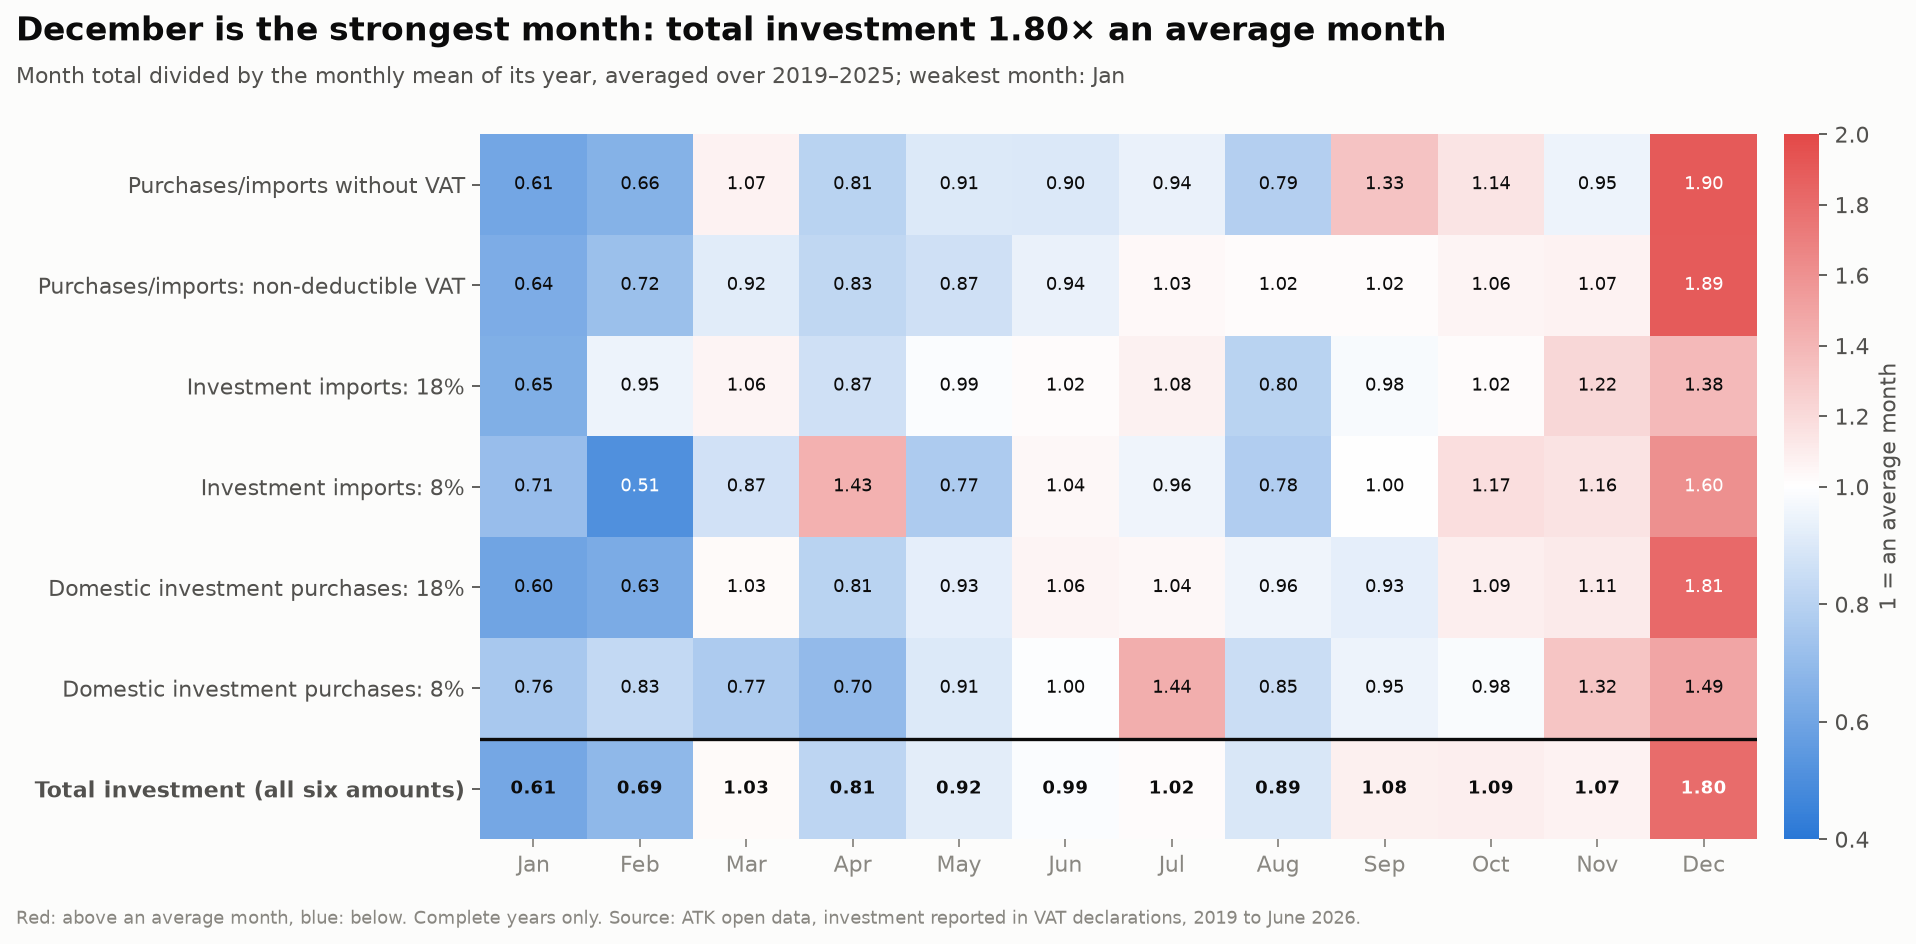

month,1,2,3,4,5,6,7,8,9,10,11,12
measure,,,,,,,,,,,,
Mixed: no VAT,0.61,0.66,1.07,0.81,0.91,0.90,0.94,0.79,1.33,1.14,0.95,1.90
Mixed: non-deductible VAT,0.64,0.72,0.92,0.83,0.87,0.94,1.03,1.02,1.02,1.06,1.07,1.89
Imports 18%,0.65,0.95,1.06,0.87,0.99,1.02,1.08,0.80,0.98,1.02,1.22,1.38
Imports 8%,0.71,0.51,0.87,1.43,0.77,1.04,0.96,0.78,1.00,1.17,1.16,1.60
Domestic 18%,0.60,0.63,1.03,0.81,0.93,1.06,1.04,0.96,0.93,1.09,1.11,1.81
Domestic 8%,0.76,0.83,0.77,0.70,0.91,1.00,1.44,0.85,0.95,0.98,1.32,1.49
TOTAL,0.61,0.69,1.03,0.81,0.92,0.99,1.02,0.89,1.08,1.09,1.07,1.80


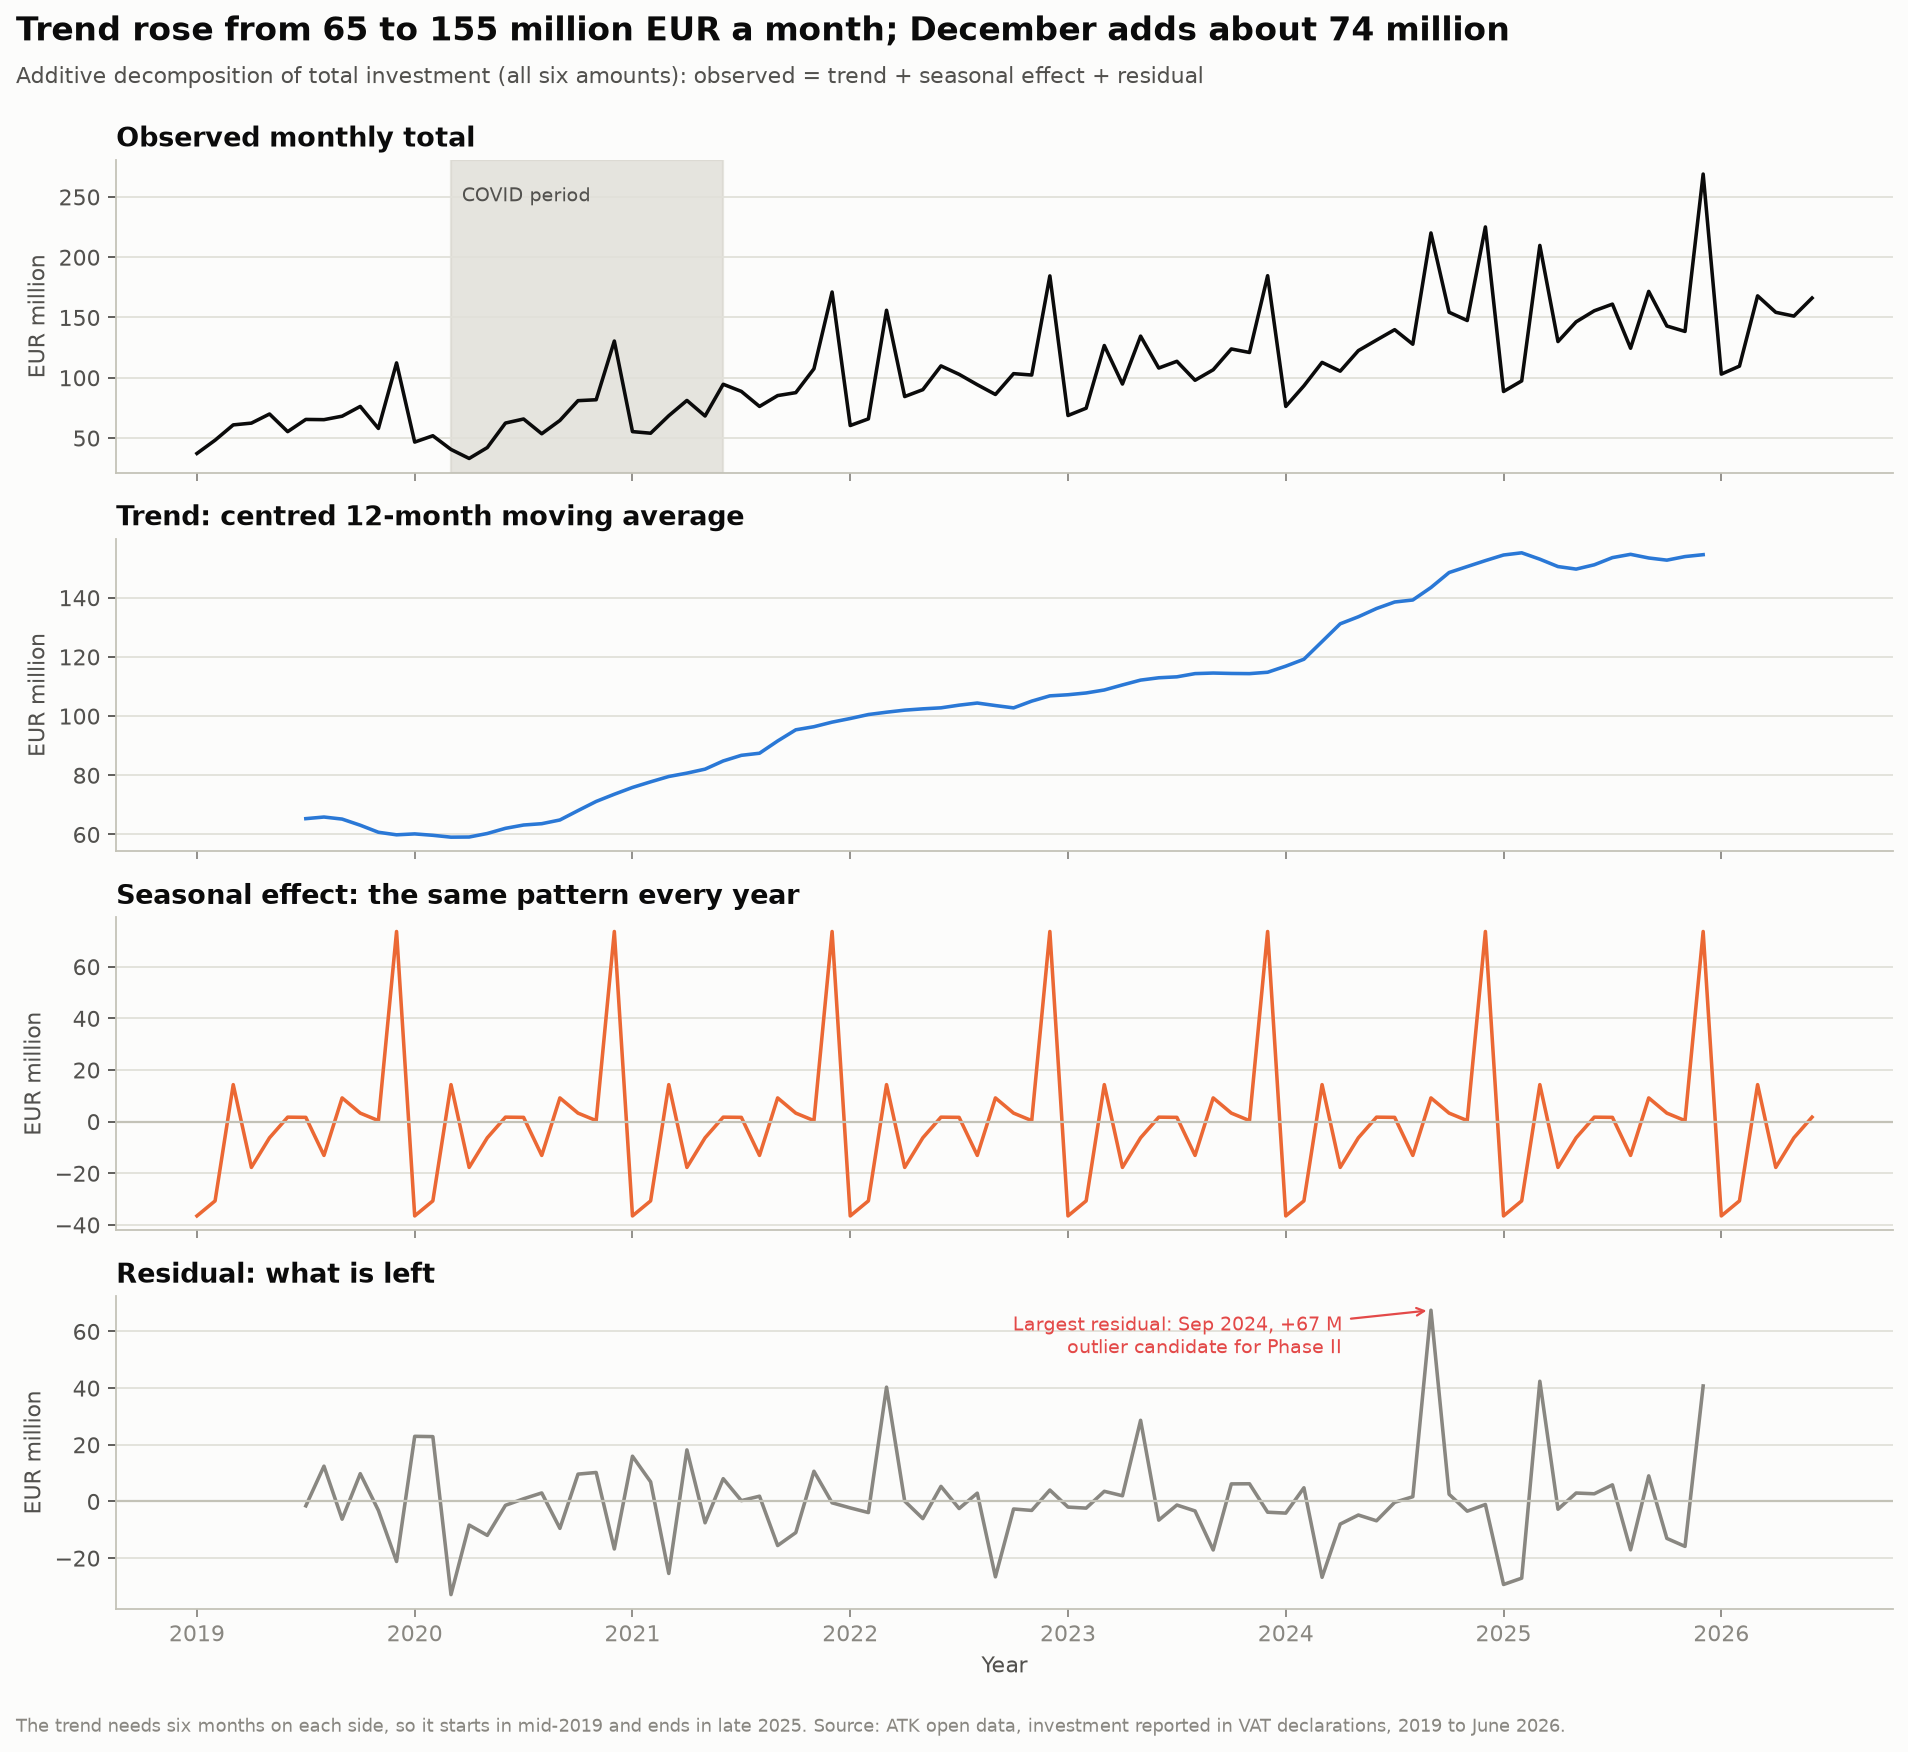

In [7]:
figure('a04_seasonality_heatmap.png')
seasonality = read_table('seasonality')
display(seasonality.pivot(index='measure', columns='month', values='seasonality_index').loc[MEASURES].rename(index=SHORT).round(2))
figure('a03_decomposition.png')

**Reading:**
- **December is by far the strongest month: 1.80×** an average month for total investment, and the strongest month for every one of the six amounts. January (0.61) and February (0.69) are the weakest. A plausible reason is year-end investment for tax and budget planning; the data show the pattern, not its cause.
- The trend rose from about **EUR 65 million a month (mid-2019) to 155 million (late 2025)**, flattening during 2025. December adds about **EUR 74 million** on top of the trend.
- The largest residual is **September 2024 (+EUR 67 million)**. It coincides with the single largest source record (about EUR 97.5 million, Prishtinë, sector `Mungon aktiviteti`) and is the first outlier candidate for Phase II.

## 5. Transformation: skewness before and after

$$
x' = \log(1 + x) \qquad z = \frac{x - \bar x}{s}
$$

`log1p` compresses large values; the z-score puts series of different size on one scale. The index 2019 = 100 (section 2) and seasonal adjustment ($V_t - S_t$) are the other transformations of this stage.

In [8]:
skewness = read_table('skewness')
display(skewness.query("window == 'reported'").set_index('measure').loc[MEASURES]
        [['months', 'negative_months', 'skew_raw', 'skew_log1p', 'skew_seasonally_adjusted', 'min_max_ratio']].rename(index=SHORT).round(2))

,months,negative_months,skew_raw,skew_log1p,skew_seasonally_adjusted,min_max_ratio
measure,,,,,,
Mixed: no VAT,90,0,2.20,0.36,1.69,14.50
Mixed: non-deductible VAT,90,0,1.47,-0.62,0.33,17.78
Imports 18%,90,0,0.87,-0.12,0.70,7.99
Imports 8%,90,0,3.35,0.59,2.98,44.72
Domestic 18%,90,0,1.09,-0.31,0.46,9.24
Domestic 8%,90,0,5.47,1.03,4.47,18.86
TOTAL,90,0,0.95,-0.10,0.35,8.13


**Reading:** monthly totals are right-skewed. For total investment `log1p` brings the skewness from **0.95 to -0.10**, almost symmetric; the strongest effect is for domestic purchases at 8% (5.47 → 1.03). Removing the seasonal effect alone also lowers it (total: 0.35), which shows that part of the skewness is simply December. No monthly total is negative: the 79 negative source records are offset within their month.

## 6. Discretization and binarization

Monthly year-over-year growth is discretised with **fixed economic thresholds**:

| Growth | Class |
|---|---|
| < −20% | `strong_decline` |
| −20% to −5% | `decline` |
| −5% to +5% | `stable` |
| +5% to +20% | `growth` |
| > +20% | `strong_growth` |

The choice is checked against the two mechanical methods: **equal width** (`pd.cut` into 5 bins of equal width) and **equal frequency** (`pd.qcut` into quintiles).

Binary indicators (0/1): `growth_positive` (growth > 0), `mom_positive` (above the previous month), `above_trend` (above the 12-month moving average), `is_covid`, `is_lockdown`, `is_full_year`.

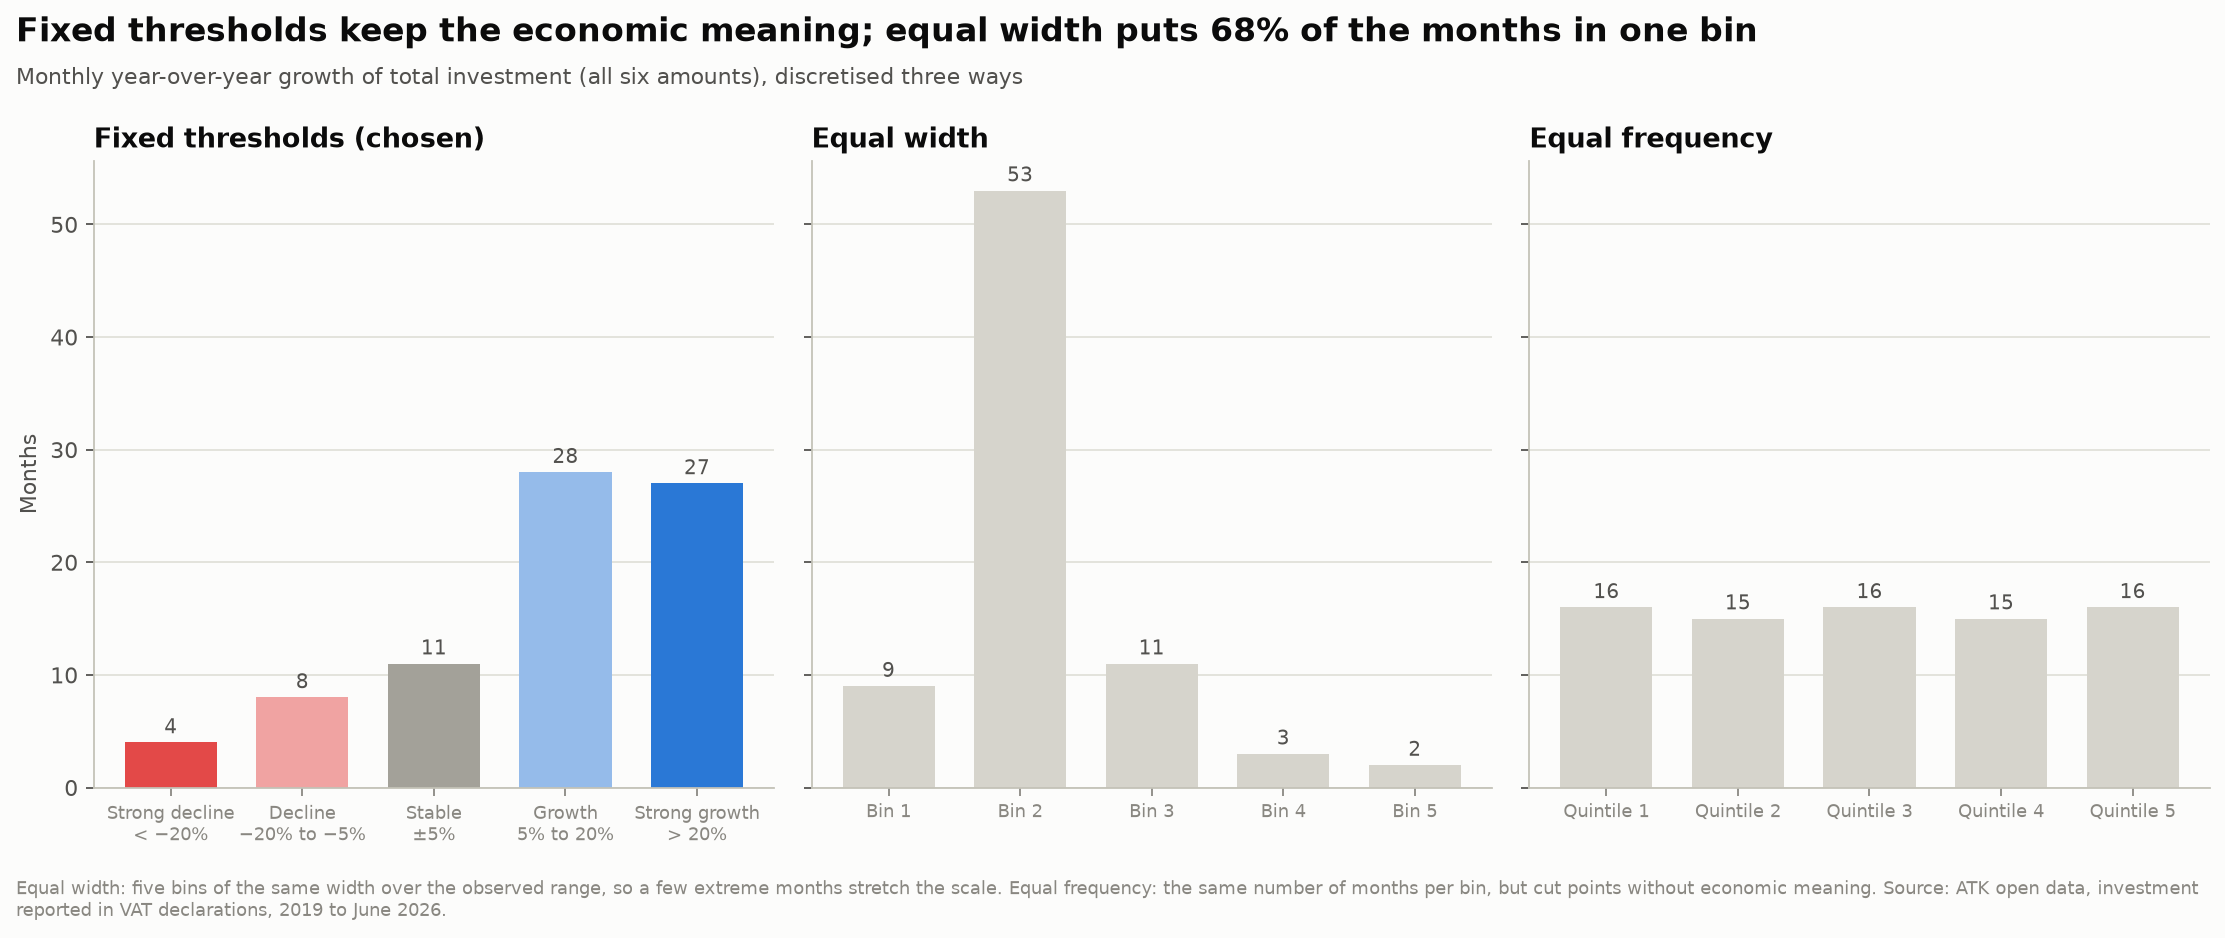

method,equal_frequency,equal_width,fixed_thresholds
measure,,,
Mixed: no VAT,0.21,0.49,0.46
Mixed: non-deductible VAT,0.21,0.49,0.32
Imports 18%,0.21,0.45,0.45
Imports 8%,0.21,0.87,0.55
Domestic 18%,0.21,0.67,0.44
Domestic 8%,0.21,0.49,0.44
TOTAL,0.21,0.68,0.36


,growth_positive,mom_positive,above_trend
measure,,,
Mixed: no VAT,0.59,0.54,0.42
Mixed: non-deductible VAT,0.63,0.58,0.46
Imports 18%,0.73,0.58,0.62
Imports 8%,0.59,0.54,0.42
Domestic 18%,0.82,0.61,0.56
Domestic 8%,0.55,0.54,0.41
TOTAL,0.81,0.6,0.56


In [9]:
figure('a07_growth_class_methods.png')
largest = read_table('growth_class_largest_share')
display(largest.query("window == 'reported'").pivot(index='measure', columns='method', values='largest_class_share').loc[MEASURES].rename(index=SHORT).round(2))
monthly = read_table('monthly_discretized').query("window == 'reported'")
display(monthly.groupby('measure')[['growth_positive', 'mom_positive', 'above_trend']].mean().loc[MEASURES].rename(index=SHORT).round(2))

**Reading:**
- With fixed thresholds the 78 comparable months of total investment split into **4 strong decline, 8 decline, 11 stable, 28 growth and 27 strong growth**. Every class has an economic meaning.
- **Equal width puts 68% of the months in one bin**: a few extreme months stretch the range, so the bins say little. Equal frequency is balanced by construction (about 20% each), but its cut points change with the data and have no economic meaning. Fixed thresholds are therefore used.
- `growth_positive`: total investment was above the same month of the previous year in **81%** of the months; in 2020 only 58%, in 2021 every month (100%).

## 7. Sampling: is the 2020 decline real?

63% of the source records carry zero in every amount, so a year's total rests on relatively few groups. Two checks:

1. **Bootstrap:** within each year the source records are resampled with replacement (200 replicates, seed 42) and totals and growth are recomputed; the 2.5 and 97.5 percentiles give a 95% interval. A change is **clear** when the whole interval is on one side of zero, and it is only flagged when both years cover the same months.
2. **10% samples against the population:** a simple random sample and a sample stratified by month (20 draws each) are scaled up by 10 and compared with the full data.

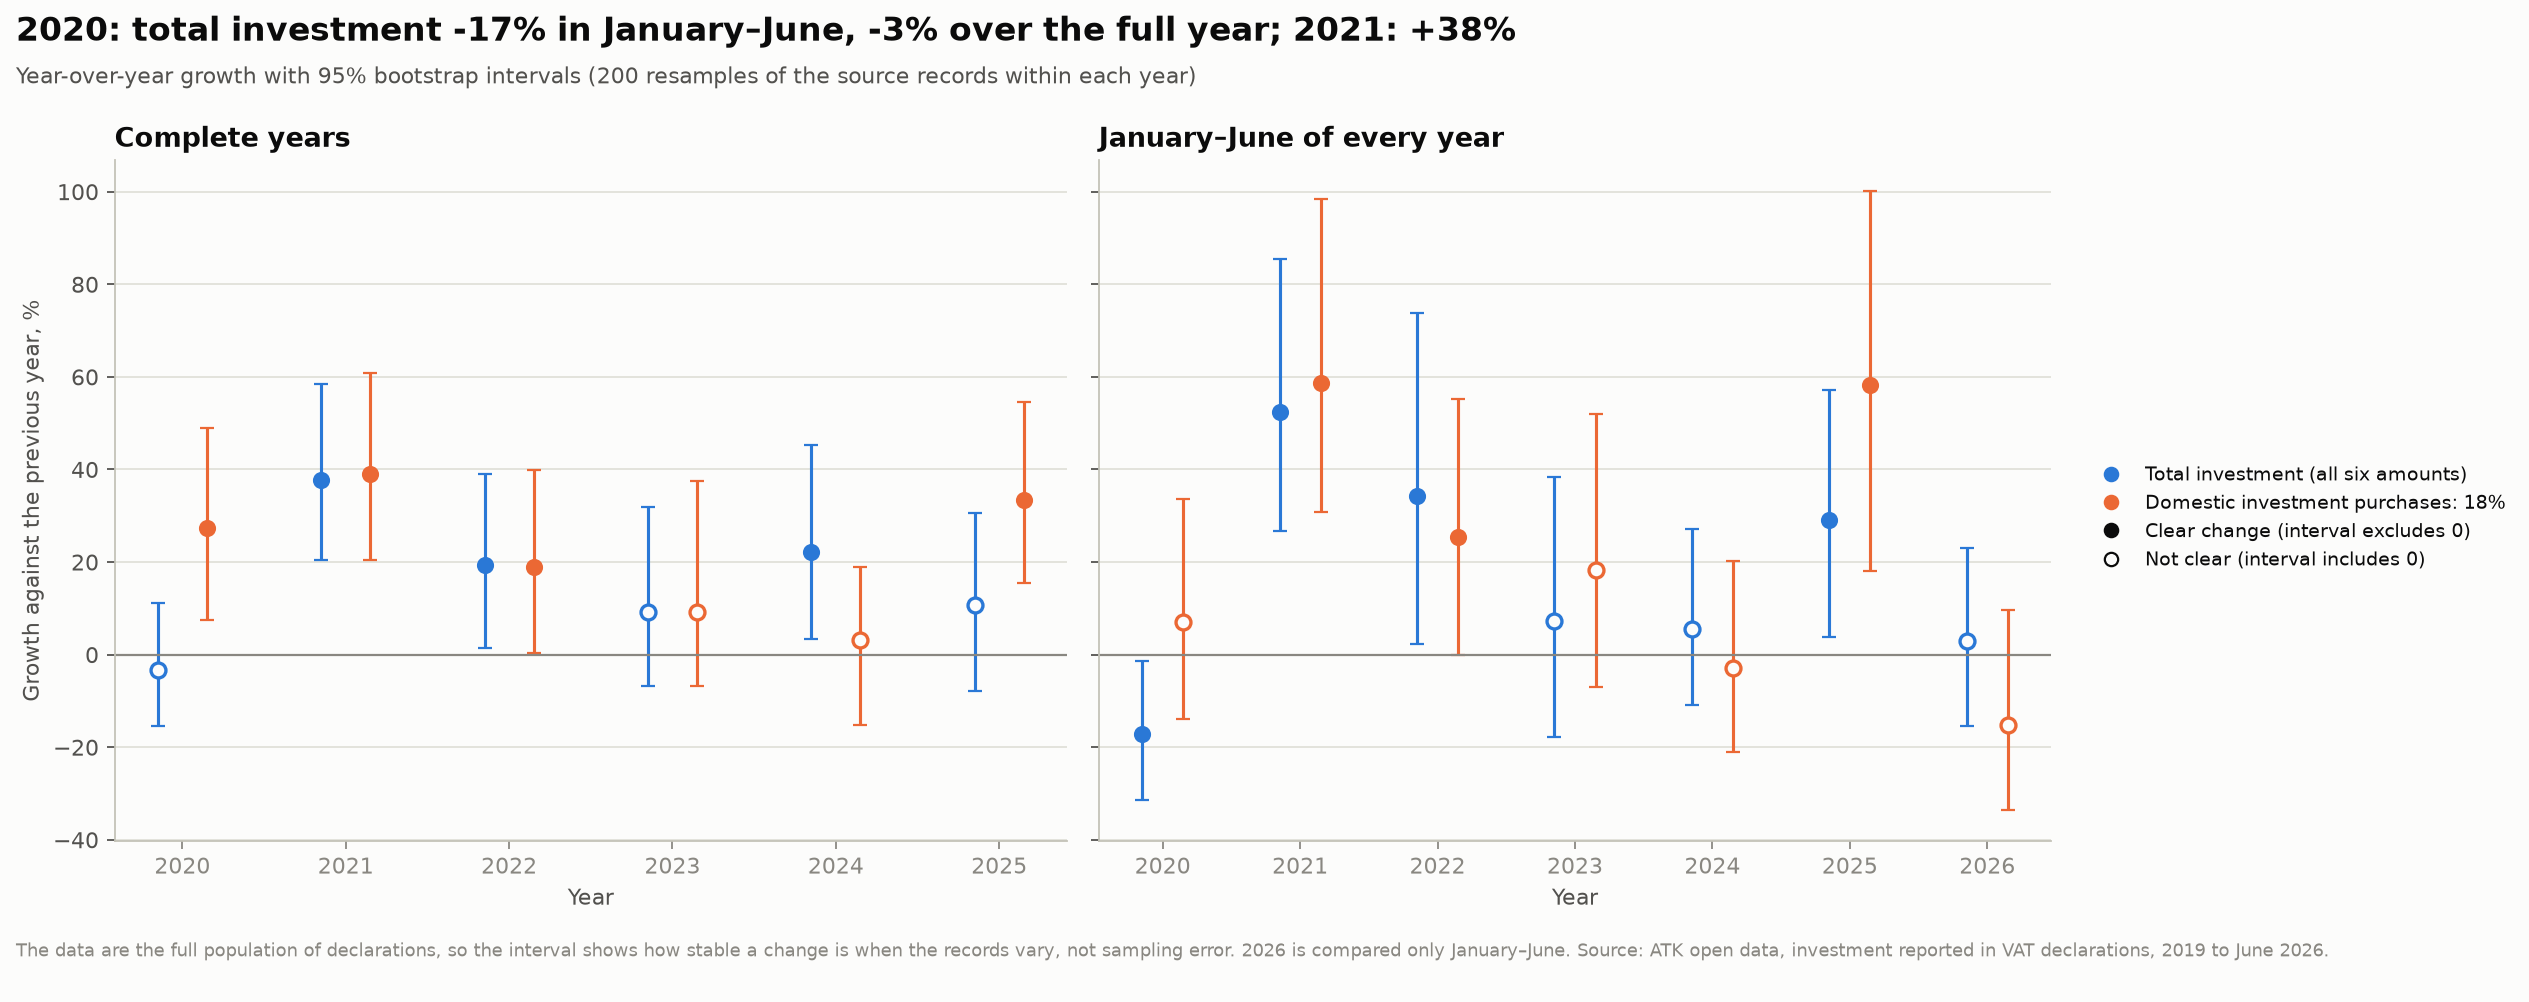

,window,year,yoy_pct,yoy_ci_low,yoy_ci_high,significant_decline,significant_growth
13,reported,2020,-3.3,-15.5,11.2,False,False
20,reported,2021,37.7,20.5,58.5,False,True
27,reported,2022,19.4,1.5,38.9,False,True
34,reported,2023,9.3,-6.8,31.8,False,False
41,reported,2024,22.2,3.4,45.3,False,True
48,reported,2025,10.8,-7.9,30.6,False,False
69,jan_jun,2020,-17.1,-31.5,-1.4,True,False
76,jan_jun,2021,52.5,26.6,85.5,False,True
83,jan_jun,2022,34.3,2.2,73.7,False,True
90,jan_jun,2023,7.2,-17.7,38.3,False,False


,window,method,mean_abs_relative_error_total_pct,mean_abs_error_yoy_pp
6,reported,simple_random,13.2,21.8
13,reported,stratified_by_period,12.0,17.8
20,jan_jun,simple_random,17.7,30.9
27,jan_jun,stratified_by_period,18.8,31.9


In [10]:
figure('a06_yoy_bootstrap_ci.png')
bootstrap = read_table('bootstrap_ci')
display(bootstrap.query('measure == @TOTAL and comparable')[['window', 'year', 'yoy_pct', 'yoy_ci_low', 'yoy_ci_high', 'significant_decline', 'significant_growth']].round(1))
display(read_table('sample_sensitivity').query('measure == @TOTAL')[['window', 'method', 'mean_abs_relative_error_total_pct', 'mean_abs_error_yoy_pp']].round(1))

**Reading:**
- **Full year 2020: -3% (95% interval -15% to +11%)**. The interval includes zero, so over the whole year the pandemic did not clearly reduce investment.
- **January–June 2020: -17% (95% interval -32% to -1%)**. Here the decline is clear: the shock is real, but concentrated in the first half of the year.
- **2021: +38% (95% interval +20% to +59%)**, a clear recovery. **January–June 2026: +3% (95% interval -15% to +23%)**, i.e. stable against 2025.
- A 10% sample misses the annual total by about **13%** on average and the growth rate by about **22 percentage points**; stratifying by month barely helps (12%, 18 pp). A few very large records decide the totals, so all analyses use the full data; this stage documents why.
- The data are the full population of declarations, so the bootstrap shows how stable a change is when the records vary, not sampling error in the classical sense.

## 8. Summary

1. **Steady growth:** total investment rose from EUR 780 million (2019) to EUR 1,835 million (2025), 2.35×, about 15% a year with an almost straight trend (R² = 0.97).
2. **COVID-19: deep but short.** The lockdown cut investment by up to 47% (April 2020); it was back at the 2019 level after 7 months, and the full year 2020 ended only 3% lower. Domestic purchases recovered in 4 months, imports in 13; services (accommodation, transport, information and communication) took longest.
3. **Strong seasonality:** December is 1.8× an average month, January–February the weakest.
4. **2026 is stable:** January–June 2026 is +3% against January–June 2025.
5. **Phase II:** September 2024 is the clearest anomaly, linked to one EUR 97.5 million record.

## 9. Limitations

- The amounts are **self-declared** in VAT declarations, not verified investment; the currency is assumed to be EUR, as the ATK file does not state it.
- **2026 covers January–June only**: it is compared through the `jan_jun` window and left out of the trend and seasonality.
- Recovery is measured against the **2019 monthly mean**. Investment was growing before the pandemic, so "back at the 2019 level" is not "back on the pre-pandemic trend".
- The high growth rates of spring 2021 (up to +145% in April) are mostly a **base effect** of the very low spring 2020.
- Imports at 8% are small (about EUR 2–8 million a year), so their growth rates and indices are volatile.
- Negative records (79 corrections) stay in the totals; extreme records are flagged, not removed. Outliers are the subject of Phase II.
- `Mungon aktiviteti` and `Person Fizik` are kept in the national totals but excluded from the sector comparison.

## 10. Validation and references

The cell below checks that the saved tables are exactly the ones the pipeline validated.

In [11]:
assert all(digest(TABLES / f'{name}.csv') == sha for name, sha in status['tables'].items()), 'A table changed after validation'
assert set(status['figures']) == {path.name for path in FIGURES.glob('*.png')}
print(f"Validation: {len(status['tables'])} table hashes and {len(status['figures'])} figures match the PASS run.")

Validation: 16 table hashes and 9 figures match the PASS run.


**References**
- Data: [ATK — Open Data](https://www.atk-ks.org/open-data/) (investment reported in VAT declarations).
- Classical decomposition: [Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, 3.4 Classical decomposition](https://otexts.com/fpp3/classical-decomposition.html).
- Bootstrap: [Bootstrapping (statistics)](https://en.wikipedia.org/wiki/Bootstrapping_(statistics)).
- Discretization: [`pandas.cut`](https://pandas.pydata.org/docs/reference/api/pandas.cut.html) and [`pandas.qcut`](https://pandas.pydata.org/docs/reference/api/pandas.qcut.html).